# 01 · Campaign audit — every headline number, recomputed from the ledgered data

**What this notebook is.** The Adversarial Replication Flywheel prototype ran a preregistered
campaign on BlueQubit (`mps.cpu`, TEST account, closed 2026-10-07): 10 rounds of a
*flywheel* arm whose proposals use earlier rounds' results vs 10 rounds of an equal-budget *no-memory control* arm
on a frozen 48-circuit RCS suite, then **one** locked-holdout evaluation. The README, report and
evidence appendix state the results. This notebook re-derives them from the per-circuit rows the harness wrote,
with its own code, and checks each against the recorded value.

**Bottom line.** All checks pass (verdict table at the end): every headline number follows from the ledger-pinned
per-circuit rows by the preregistered rules, including the negative results (no flywheel promotion, a missed frozen
prediction). One deviation is disclosed and not counted as a check (§1), and §4 shows how close to the bootstrap
boundary the campaign's only promotion was.

**No API key, no cloud jobs, no campaign code imported** — only `numpy`, `matplotlib`, and the
data bundle in `data/test-campaign/` (byte-identical copies of the campaign files, sha256-listed
in `PROVENANCE.json`, built by `tools/build_bundle.py`). Runs in seconds on a laptop.

**What is checked**
1. Bundle integrity, then **ledger integrity**: each round's `metrics.json` against the sha256 the
   experiment ledger pinned at record time; SPEC/PREREGISTRATION files against their registration pins.
2. The job ledger: job counts per device, statuses, total spend.
3. Baseline and noise floor → `min_delta`.
4. **All 20 round decisions**: paired bootstrap CI, cost ratio and the gate verdict, recomputed.
5. The one-shot **holdout**: means, paired deltas and CIs.
6. The **frozen prediction**: formula, band, score.
7. The **claims ledger**: every job ID cited by a claim resolves to a completed job.

In [1]:
import csv, json, re, collections, pathlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import nbcommon as C

C.style()
B = C.load_bundle()          # $NB_BUNDLE or "test-campaign"; raises if any file differs from PROVENANCE.json
v = B.verify()
print(f"bundle: {B.prov['n_files']} files from tree '{B.prov['source_tree']}', "
      f"built {B.prov['built_at']}; sha256 mismatches: {len(v['mismatches'])}")
CHECKS = []                                   # (section, check, recorded, recomputed, ok)
DISCLOSED = []                                # known, documented deviations: shown in the verdict, not counted as checks

def check(section, name, recorded, recomputed, ok=None, fmt="{}"):
    if ok is None:
        ok = recorded == recomputed
    CHECKS.append((section, name, fmt.format(recorded), fmt.format(recomputed), bool(ok)))

bundle: 100 files from tree 'prototype', built 2026-10-11T15:56:14+00:00; sha256 mismatches: 0


## 1 · Ledger integrity

The campaign's experiment ledger (`ledger/experiments.json`) pins three hashes per experiment:
SPEC at registration, PREREGISTRATION at registration, and each recorded run's `metrics.json`
at record time. A promotion is refused by code if any of them changes. Here we re-hash the
bundled copies.

In [2]:
L = B.json("ledger/experiments.json")["experiments"]
m_ok = m_n = s_ok = s_n = p_ok = p_n = 0
prereg_mismatch = []
for exp_id, e in L.items():
    for att in e.get("attempts", []):
        m_n += 1
        m_ok += C.sha256(B.path(att["run_dir"]) / "metrics.json") == att["metrics_sha256"]
    s_n += 1
    s_ok += C.sha256(B.path(e["spec_path"])) == e["spec_sha256"]
    pre = B.path(e["spec_path"]).parent / "PREREGISTRATION.json"
    if pre.exists() and e.get("preregistration_sha256"):
        p_n += 1
        if C.sha256(pre) == e["preregistration_sha256"]:
            p_ok += 1
        else:
            prereg_mismatch.append(exp_id)
print(f"experiments in ledger: {len(L)}")
print(f"recorded metrics.json matching the ledger pin: {m_ok}/{m_n}")
print(f"SPEC.md matching the registration pin:        {s_ok}/{s_n}")
print(f"PREREGISTRATION.json matching the pin:         {p_ok}/{p_n}   mismatches: {prereg_mismatch}")
check("ledger", "recorded metrics.json == ledger pin", f"{m_n}/{m_n}", f"{m_ok}/{m_n}")
check("ledger", "SPEC.md == registration pin", f"{s_n}/{s_n}", f"{s_ok}/{s_n}")
DISCLOSED.append(("ledger", "PREREGISTRATION.json == registration pin", f"{p_n}/{p_n}", f"{p_ok}/{p_n}"))

experiments in ledger: 31
recorded metrics.json matching the ledger pin: 29/29
SPEC.md matching the registration pin:        31/31
PREREGISTRATION.json matching the pin:         28/31   mismatches: ['EXP-006-R04', 'EXP-006-R07', 'EXP-006-R10']


Three PREREGISTRATION files do **not** match their pins. The README's *Known limitations*
discloses exactly this: *"Three control prereg files were rewritten post-hoc for timestamp-only
recovery"* (for EXP-006-R04 the round was killed before recording and re-run under the fixed scorer, per
`runs/flywheel/20261006T131302Z_r4/NOTE-BUG.md`; the campaign log documents the other two). That disclosure is a
claim too, so we test it constructively: if the **only** change was the `frozen_at` timestamp, then
setting `frozen_at` back to the ledger's `registered_at` must reproduce the pinned hash byte-for-byte.

In [3]:
import hashlib
for exp_id in prereg_mismatch:
    e = L[exp_id]
    raw = (B.path(e["spec_path"]).parent / "PREREGISTRATION.json").read_text()
    current = re.search(r'"frozen_at": "([^"]+)"', raw).group(1)
    restored = raw.replace(current, e["registered_at"])
    match = hashlib.sha256(restored.encode()).hexdigest() == e["preregistration_sha256"]
    print(f"{exp_id}: frozen_at now {current}; with frozen_at = registered_at "
          f"{e['registered_at']} -> sha256 matches ledger pin: {match}")
    check("ledger", f"{exp_id} prereg differs ONLY in frozen_at", True, match)

EXP-006-R04: frozen_at now 2026-10-06T13:20:05+00:00; with frozen_at = registered_at 2026-10-06T13:13:02+00:00 -> sha256 matches ledger pin: True
EXP-006-R07: frozen_at now 2026-10-06T19:42:23+00:00; with frozen_at = registered_at 2026-10-06T18:45:26+00:00 -> sha256 matches ledger pin: True
EXP-006-R10: frozen_at now 2026-10-07T02:00:58+00:00; with frozen_at = registered_at 2026-10-07T01:08:07+00:00 -> sha256 matches ledger pin: True


## 2 · The job ledger

`runs/report/jobs_export.csv` is the export of every job in the campaign's job ledger
(provider job ID, experiment, device, status, cost). EXP-008 is the separate gate-calibration
experiment (notebook 02); the campaign itself is everything else.

The few jobs that did not complete (listed in the output) are `pauli-path` probes from EXP-002B that the service
rejected with `FAILED_VALIDATION`: their truncation threshold was too small for the circuit and observable, which the
service flagged as a memory-overflow risk (error text recorded in the bundled `runs/20261006T030424Z_g15b/metrics.json`;
notebook 04 explains why). Spend is the summed `cost_usd` column; the campaign ran on a TEST account.

In [4]:
jobs = list(csv.DictReader(open(B.path("runs/report/jobs_export.csv"))))
camp = [j for j in jobs if j["exp_id"] != "EXP-008-GATE-CALIBRATION"]
dev = collections.Counter(j["device"] for j in camp)
status = collections.Counter(j["run_status"] for j in jobs)
spend = sum(float(j["cost_usd"] or 0) for j in jobs)
hold = [j for j in jobs if j["exp_id"] == "EXP-007-HOLDOUT"]
print(f"all exported jobs: {len(jobs)}  (EXP-008: {len(jobs) - len(camp)}; campaign: {len(camp)})")
print(f"campaign jobs by device: {dict(dev)}")
print(f"statuses (all): {dict(status)}")
print(f"non-completed: {[(j['exp_id'], j['device'], j['job_name']) for j in jobs if j['run_status'] != 'COMPLETED']}")
print(f"total billed cost_usd over all jobs: {spend:.2f}")
print(f"holdout jobs: {len(hold)}")
# Numbers the campaign README states for this bundle (TEST campaign: README.md, "Total spend" paragraph:
# 905 ledgered jobs = 878 mps.cpu + 12 cpu + 15 pauli-path, including the 36 holdout jobs, $0.00).
README_STATES = {"test-campaign": dict(jobs=905, devices="878 / 12 / 15", holdout=36, usd="0.00")}
st = README_STATES.get(B.prov["label"])
if st is None:
    print(f"no README figures registered for bundle '{B.prov['label']}': device/spend checks are reported, not compared")
else:
    check("jobs", "campaign jobs (README)", st["jobs"], len(camp))
    check("jobs", "mps.cpu / cpu / pauli-path (README)", st["devices"],
          f"{dev['mps.cpu']} / {dev['cpu']} / {dev['pauli-path']}")
    check("jobs", "holdout jobs (README)", st["holdout"], len(hold))
    check("jobs", "total spend USD (README)", st["usd"], f"{spend:.2f}")

per_exp = collections.Counter(j["exp_id"] for j in camp)
fam = collections.OrderedDict()
for k, n in per_exp.items():
    key = ("flywheel rounds (EXP-005-Rxx)" if re.match(r"EXP-005-R\d", k) else
           "control rounds (EXP-006-Rxx)" if k.startswith("EXP-006") else
           "noise canaries" if "CANARY" in k else k)
    fam[key] = fam.get(key, 0) + n
display(Markdown("| experiment family | jobs |\n|---|---|\n" +
                 "\n".join(f"| {k} | {n} |" for k, n in fam.items())))

all exported jobs: 1097  (EXP-008: 192; campaign: 905)
campaign jobs by device: {'cpu': 12, 'mps.cpu': 878, 'pauli-path': 15}
statuses (all): {'COMPLETED': 1094, 'FAILED_VALIDATION': 3}
non-completed: [('EXP-002B-G15B-PIVOT-SCREEN', 'pauli-path', 'g15c-A20-w10-e1e-05'), ('EXP-002B-G15B-PIVOT-SCREEN', 'pauli-path', 'g15c-A20-w10-e3e-05'), ('EXP-002B-G15B-PIVOT-SCREEN', 'pauli-path', 'g15c-B32-w4-e1e-05')]
total billed cost_usd over all jobs: 0.00
holdout jobs: 36


| experiment family | jobs |
|---|---|
| EXP-001-G1-TUTORIAL-BASELINE | 24 |
| EXP-002B-G15B-PIVOT-SCREEN | 17 |
| EXP-004-G3-BASELINE | 84 |
| flywheel rounds (EXP-005-Rxx) | 360 |
| control rounds (EXP-006-Rxx) | 360 |
| noise canaries | 24 |
| EXP-007-HOLDOUT | 36 |

## 3 · Baseline and the noise floor

The G3 baseline evaluated the round-0 incumbent (uniform χ=64, 20k shots) **twice** on the 12
validation circuits. The per-circuit differences between two identical runs measure pure
run-to-run noise; the preregistered formula (EXP-004 PREREGISTRATION) is
`min_delta = max(2 · sd(paired deltas), 0.005)`.

In [5]:
runs = {p.parent.name: json.loads(p.read_text())
        for p in sorted(B.path("runs/flywheel").glob("*/metrics.json"))}
g3 = next(v for k, v in runs.items() if k.endswith("_g3"))
r1, r2 = g3["val_run1"]["rows"], g3["val_run2"]["rows"]
assert [a["id"] for a in r1] == [b["id"] for b in r2]
noise = np.array([a["xeb"] - b["xeb"] for a, b in zip(r1, r2)])
sd = float(np.std(noise, ddof=1))
min_delta = max(2 * sd, 0.005)
summary = B.json("runs/report/summary.json")
base_mean = float(np.mean([r["xeb"] for r in r1]))
print(f"baseline mean val XEB: {base_mean:.6f}   (summary.json: {summary['baseline']['mean_xeb_val']:.6f})")
print(f"paired noise sd:       {sd:.6f}   (summary.json: {summary['noise_sd_paired']:.6f})")
print(f"min_delta:             {min_delta:.6f}   (summary.json: {summary['min_delta']:.6f})")
check("baseline", "baseline mean val XEB", summary["baseline"]["mean_xeb_val"], base_mean,
      ok=abs(base_mean - summary["baseline"]["mean_xeb_val"]) < 1e-12, fmt="{:.6f}")
check("baseline", "noise sd (paired, ddof=1)", summary["noise_sd_paired"], sd, ok=sd == summary["noise_sd_paired"], fmt="{:.6f}")
check("baseline", "min_delta = max(2·sd, 0.005)", summary["min_delta"], min_delta, ok=min_delta == summary["min_delta"], fmt="{:.6f}")

baseline mean val XEB: 0.953184   (summary.json: 0.953184)
paired noise sd:       0.013476   (summary.json: 0.013476)
min_delta:             0.026952   (summary.json: 0.026952)


## 4 · All 20 round decisions, recomputed

Each round applies **one** mutation to its arm's incumbent and evaluates it on the 12 val
circuits. The decision statistic is the mean per-circuit paired delta (candidate − incumbent)
with a percentile bootstrap 95% CI (seed 3, 5000 resamples — `nbcommon.paired_delta` is a line-for-line
re-implementation of `src/metrics.py::paired_delta`). The preregistered gate PROMOTES only if
**mean Δ > min_delta AND CI excludes 0 AND cost ratio ≤ 1.02**. Each arm keeps its own incumbent
lineage: we replay both lineages from round 0, promoting exactly when our recomputed gate says so.

In [6]:
recorded = {(r["arm"], r["round"]): r for r in B.json("runs/report/rounds.json")}
inc = {arm: (g3["val_run1"]["rows"], g3["val_run1"]["cost_min"]) for arm in ("flywheel", "control")}
replay = []
for name in sorted(k for k in runs if re.search(r"_r\d+(_control)?$", k)):
    m = runs[name]
    arm, k = m["arm"], m["round"]
    inc_rows, inc_cost = inc[arm]
    ref = {r["id"]: r["xeb"] for r in inc_rows}
    d = [r["xeb"] - ref[r["id"]] for r in m["val"]["rows"]
         if r["xeb"] is not None and ref.get(r["id"]) is not None]
    s = C.paired_delta(d)
    cost_ratio = m["val"]["cost_min"] / inc_cost
    verdict = C.gate(s["mean_delta"], s["ci_low"], cost_ratio, min_delta)
    rec = recorded[(arm, k)]
    same = (s["mean_delta"] == rec["mean_delta"] and [s["ci_low"], s["ci_high"]] == rec["ci"]
            and abs(cost_ratio - rec["cost_ratio"]) < 1e-9 and verdict == rec["accepted"])
    replay.append(dict(arm=arm, round=k, family=m["mutation"]["family"], value=m["mutation"]["value"],
                       delta=s["mean_delta"], lo=s["ci_low"], hi=s["ci_high"], cost=cost_ratio,
                       verdict=verdict, recorded=rec["accepted"], same=same, n=s["n"], d=d))
    if verdict:  # promotion: this arm's incumbent becomes the candidate
        inc[arm] = (m["val"]["rows"], m["val"]["cost_min"])

n_same = sum(r["same"] for r in replay)
print(f"rounds replayed: {len(replay)}; identical to the record (Δ, both CI bounds, cost ratio, verdict): {n_same}/{len(replay)}")
for arm in ("flywheel", "control"):
    print(f"{arm:8s} promotions: recomputed {sum(r['verdict'] for r in replay if r['arm'] == arm)}"
          f" / recorded {summary['promotions'][arm]}")
check("rounds", "round decisions identical to record", f"{len(replay)}/{len(replay)}", f"{n_same}/{len(replay)}")
check("rounds", "promotions flywheel / control", f"{summary['promotions']['flywheel']} / {summary['promotions']['control']}",
      f"{sum(r['verdict'] for r in replay if r['arm']=='flywheel')} / {sum(r['verdict'] for r in replay if r['arm']=='control')}")

hdr = "| arm | r | mutation | mean Δ | 95% CI | cost ratio | verdict | = record |\n|---|---|---|---|---|---|---|---|\n"
display(Markdown(hdr + "\n".join(
    f"| {r['arm']} | {r['round']} | {r['family']} = {r['value']} | {r['delta']:+.4f} | "
    f"[{r['lo']:+.4f}, {r['hi']:+.4f}] | {r['cost']:.3f} | {'**PROMOTED**' if r['verdict'] else 'rejected'} | "
    f"{'✅' if r['same'] else '❌'} |" for r in sorted(replay, key=lambda r: (r['round'], r['arm'] != 'flywheel')))))

rounds replayed: 20; identical to the record (Δ, both CI bounds, cost ratio, verdict): 20/20
flywheel promotions: recomputed 0 / recorded 0
control  promotions: recomputed 1 / recorded 1


| arm | r | mutation | mean Δ | 95% CI | cost ratio | verdict | = record |
|---|---|---|---|---|---|---|---|
| flywheel | 1 | chi_alloc = easy32hard128 | +0.0336 | [-0.0013, +0.0737] | 0.816 | rejected | ✅ |
| control | 1 | chi_alloc = easy32hard128 | +0.0344 | [+0.0010, +0.0744] | 0.819 | **PROMOTED** | ✅ |
| flywheel | 2 | chi_alloc = uniform128 | +0.0335 | [-0.0003, +0.0742] | 0.970 | rejected | ✅ |
| control | 2 | chi_alloc = uniform128 | -0.0063 | [-0.0159, +0.0029] | 1.185 | rejected | ✅ |
| flywheel | 3 | chi_alloc = easy32hard256 | +0.0419 | [-0.0056, +0.1005] | 0.848 | rejected | ✅ |
| control | 3 | chi_alloc = easy32hard256 | +0.0116 | [-0.0006, +0.0256] | 1.037 | rejected | ✅ |
| flywheel | 4 | permutation = 11 | -0.9331 | [-0.9792, -0.8820] | 1.010 | rejected | ✅ |
| control | 4 | chi_alloc = uniform256 | +0.0121 | [+0.0023, +0.0240] | 1.257 | rejected | ✅ |
| flywheel | 5 | permutation = 23 | -0.4837 | [-0.6305, -0.3230] | 1.013 | rejected | ✅ |
| control | 5 | chi_alloc = easy16hard128 | -0.0125 | [-0.0291, +0.0036] | 1.020 | rejected | ✅ |
| flywheel | 6 | permutation = 37 | -0.5373 | [-0.6567, -0.4135] | 1.028 | rejected | ✅ |
| control | 6 | chi_alloc = uniform32 | -0.1124 | [-0.2055, -0.0323] | 0.878 | rejected | ✅ |
| flywheel | 7 | shots_alloc = easy10khard30k | -0.0008 | [-0.0116, +0.0098] | 0.896 | rejected | ✅ |
| control | 7 | permutation = 11 | -0.5341 | [-0.6796, -0.3584] | 1.187 | rejected | ✅ |
| flywheel | 8 | shots_alloc = easy4khard36k | -0.0106 | [-0.0237, +0.0027] | 0.818 | rejected | ✅ |
| control | 8 | permutation = 23 | -0.5679 | [-0.6939, -0.4290] | 1.150 | rejected | ✅ |
| flywheel | 9 | permutation = 211 | -0.4255 | [-0.5774, -0.2518] | 1.018 | rejected | ✅ |
| control | 9 | permutation = 37 | -0.5963 | [-0.6986, -0.4862] | 1.169 | rejected | ✅ |
| flywheel | 10 | permutation = 252 | -0.4638 | [-0.6112, -0.2942] | 1.003 | rejected | ✅ |
| control | 10 | permutation = 51 | -0.4519 | [-0.6080, -0.2868] | 1.108 | rejected | ✅ |

**How firm is each verdict?** Where a candidate's mean cleared `min_delta` and the cost bar, its verdict rests only
on whether the bootstrap CI's lower bound is above zero. The rule fixes the bootstrap seed (3), so the record is
exact; below, the identical bootstrap is re-run with 300 other seeds to show how close to the boundary those
decisions were.

In [7]:
edge = [r for r in replay if r["delta"] > min_delta and r["cost"] <= 1.02]
SEEDS_ALT = range(300)
for r in edge:
    r["promote_rate"] = np.mean([C.paired_delta(r["d"], seed=sd)["ci_low"] > 0 for sd in SEEDS_ALT])
display(Markdown(
    "| arm · round | mutation | mean Δ | CI lower bound (seed 3) | verdict | promoted under other seeds |\n|---|---|---|---|---|---|\n" +
    "\n".join(f"| {r['arm']} · r{r['round']} | {r['family']} {r['value']} | {r['delta']:+.4f} | {r['lo']:+.4f} | "
              f"{'PROMOTED' if r['verdict'] else 'rejected'} | {r['promote_rate']:.0%} |" for r in edge) +
    f"\n\n**Reading.** The preregistered rule, seed included, decided the record, and it stands. But the campaign's only "
    f"promotion (control r1) survives in {next(r['promote_rate'] for r in edge if r['verdict']):.0%} of alternative seeds, "
    f"and the flywheel's near-misses would have been promoted in "
    + ", ".join(f"{r['promote_rate']:.0%} (r{r['round']})" for r in edge if not r['verdict'] and r['arm'] == 'flywheel') +
    ". The arms diverged after round 1 at the CI boundary, so the gap between them is not evidence about memory. "
    "Notebook 02 turns this into a power calculation."))

| arm · round | mutation | mean Δ | CI lower bound (seed 3) | verdict | promoted under other seeds |
|---|---|---|---|---|---|
| flywheel · r1 | chi_alloc easy32hard128 | +0.0336 | -0.0013 | rejected | 0% |
| control · r1 | chi_alloc easy32hard128 | +0.0344 | +0.0010 | PROMOTED | 81% |
| flywheel · r2 | chi_alloc uniform128 | +0.0335 | -0.0003 | rejected | 4% |
| flywheel · r3 | chi_alloc easy32hard256 | +0.0419 | -0.0056 | rejected | 0% |

**Reading.** The preregistered rule, seed included, decided the record, and it stands. But the campaign's only promotion (control r1) survives in 81% of alternative seeds, and the flywheel's near-misses would have been promoted in 0% (r1), 4% (r2), 0% (r3). The arms diverged after round 1 at the CI boundary, so the gap between them is not evidence about memory. Notebook 02 turns this into a power calculation.

**Reading the decisions.** The chart puts each decision against the two bars it had to clear:
zero (the CI must exclude it) and `min_delta` (the mean must exceed it). Permutation rounds fall far
off the left edge: real layout damage under truncation (notebook 03); they are pinned to the edge with their value.
Flywheel r4 is different: its recorded scores are invalid because of a since-fixed unpermutation bug
(`runs/flywheel/20261006T131302Z_r4/NOTE-BUG.md` in the campaign repo). It is recomputed here exactly as recorded and
drawn in grey.

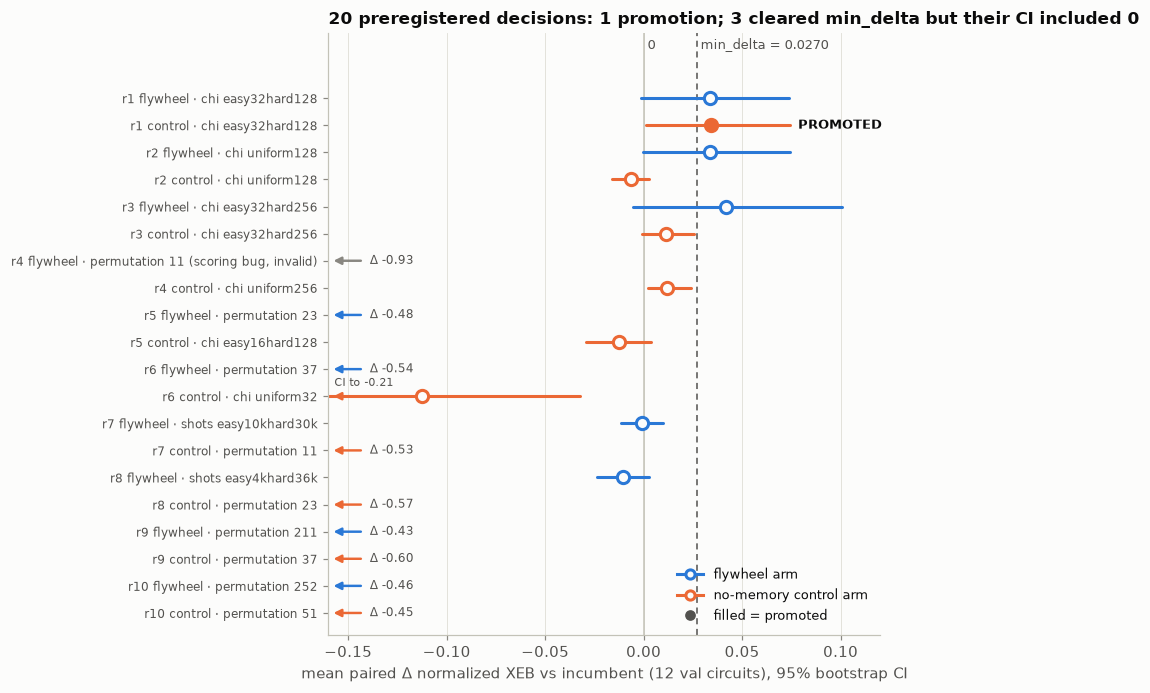

In [8]:
XMIN, XMAX = -0.16, 0.12
fig, ax = plt.subplots(figsize=(8.2, 6.4))
ax.axvline(0, color=C.AXIS, lw=1.0, zorder=1)
ax.axvline(min_delta, color=C.INK_2, lw=1.0, ls=(0, (4, 3)), zorder=1)
ax.text(min_delta + 0.002, 20.7, f"min_delta = {min_delta:.4f}", color=C.INK_2, fontsize=8.5, va="bottom")
ax.text(0.002, 20.7, "0", color=C.INK_2, fontsize=8.5, va="bottom")
ylabels = []
for i, r in enumerate(sorted(replay, key=lambda r: (r["round"], r["arm"] != "flywheel"))):
    y = 19 - i
    bug = (r["arm"], r["round"]) == ("flywheel", 4)
    col = C.MUTED if bug else C.ARM_COLOR[r["arm"]]
    ylabels.append((y, f"r{r['round']} {r['arm']} · {r['family'].replace('_alloc', '')} {r['value']}"
                       + (" (scoring bug, invalid)" if bug else "")))
    if r["hi"] < XMIN:  # entirely off-scale (permutation collapse)
        ax.annotate("", xy=(XMIN + 0.001, y), xytext=(XMIN + 0.018, y),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
        ax.text(XMIN + 0.021, y, f"Δ {r['delta']:+.2f}", color=C.INK_2, fontsize=8, va="center")
        continue
    ax.plot([max(r["lo"], XMIN), r["hi"]], [y, y], color=col, lw=2, solid_capstyle="round", zorder=2)
    if r["lo"] < XMIN:  # CI runs past the axis edge: mark the clipped end
        ax.annotate("", xy=(XMIN + 0.001, y), xytext=(XMIN + 0.012, y),
                    arrowprops=dict(arrowstyle="-|>", color=col, lw=1.6))
        ax.text(XMIN + 0.003, y + 0.38, f"CI to {r['lo']:+.2f}", color=C.INK_2, fontsize=7.5)
    ax.plot(r["delta"], y, "o", ms=8, zorder=3, color=col,
            mfc=col if r["verdict"] else C.SURFACE, mew=2)
    if r["verdict"]:
        ax.text(r["hi"] + 0.004, y, "PROMOTED", color=C.INK, fontsize=8.5, va="center", weight="bold")
ax.set_yticks([y for y, _ in ylabels], [t for _, t in ylabels], fontsize=8)
ax.set_xlim(XMIN, XMAX); ax.set_ylim(-0.8, 21.4)
ax.grid(axis="y", visible=False)
ax.set_xlabel("mean paired Δ normalized XEB vs incumbent (12 val circuits), 95% bootstrap CI")
ax.set_title(f"20 preregistered decisions: {sum(r['verdict'] for r in replay)} promotion; "
             f"{sum(1 for r in edge if not r['verdict'])} cleared min_delta but their CI included 0", fontsize=11)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=C.BLUE, marker="o", mfc=C.SURFACE, mew=2, label="flywheel arm"),
                   Line2D([], [], color=C.ORANGE, marker="o", mfc=C.SURFACE, mew=2, label="no-memory control arm"),
                   Line2D([], [], color=C.INK_2, marker="o", ls="", mfc=C.INK_2, label="filled = promoted")],
          loc="lower right", fontsize=8.5)
fig.tight_layout(); plt.show()

## 5 · The locked holdout (evaluated exactly once)

After round 10 the three configurations — the round-0 baseline, the control's final incumbent
and the flywheel's final incumbent (= baseline, never promoted) — were run **once** on the 12 sealed
holdout circuits. Paired deltas use the same bootstrap rule. In the figure below, values slightly above 1 are
finite-shot scatter (and, under truncation, the XEB bias shown in notebook 03); baseline r0 and the flywheel's final
incumbent are the same configuration run twice, so their gap shows run-to-run noise.

In [9]:
hold_run = L["EXP-007-HOLDOUT"]["attempts"][-1]["run_dir"]          # the ledger says where the one evaluation lives
H = B.json(f"{hold_run}/metrics.json")
print(f"holdout run (from the ledger): {hold_run}; evaluated_at {H['evaluated_at']}; ledger attempts: {len(L['EXP-007-HOLDOUT']['attempts'])}")
R = H["results"]
def paired(a, b):
    bm = {r["id"]: r["xeb"] for r in R[b]["rows"]}
    return [r["xeb"] - bm[r["id"]] for r in R[a]["rows"]]
hp = summary["holdout"]["paired"]
for key, (a, b) in {"control_vs_r0": ("control_final", "baseline_r0"),
                    "flywheel_vs_r0": ("flywheel_final", "baseline_r0"),
                    "flywheel_vs_control": ("flywheel_final", "control_final")}.items():
    s = C.paired_delta(paired(a, b))
    same = s["mean_delta"] == hp[key]["delta"] and [s["ci_low"], s["ci_high"]] == hp[key]["ci"]
    print(f"{key:20s} Δ {s['mean_delta']:+.5f}  CI [{s['ci_low']:+.5f}, {s['ci_high']:+.5f}]  identical to summary.json: {same}")
    check("holdout", f"paired {key} (Δ and CI)",
          f"{hp[key]['delta']:+.5f} [{hp[key]['ci'][0]:+.5f}, {hp[key]['ci'][1]:+.5f}]",
          f"{s['mean_delta']:+.5f} [{s['ci_low']:+.5f}, {s['ci_high']:+.5f}]", ok=same)
for cfg in ("baseline_r0", "control_final", "flywheel_final"):
    mean = float(np.mean([r["xeb"] for r in R[cfg]["rows"]]))
    rec = summary["holdout"]["results"][cfg]["mean_xeb_holdout"]
    check("holdout", f"{cfg} mean holdout XEB", rec, mean, ok=abs(mean - rec) < 1e-12, fmt="{:.5f}")
    print(f"{cfg:15s} mean holdout XEB {mean:.5f} over {len(R[cfg]['rows'])} circuits")

holdout run (from the ledger): runs/20261007T022513Z_holdout; evaluated_at 2026-10-07T03:57:14+00:00; ledger attempts: 1
control_vs_r0        Δ +0.05068  CI [+0.01327, +0.08967]  identical to summary.json: True
flywheel_vs_r0       Δ -0.00652  CI [-0.01492, +0.00155]  identical to summary.json: True
flywheel_vs_control  Δ -0.05720  CI [-0.09679, -0.02103]  identical to summary.json: True
baseline_r0     mean holdout XEB 0.93401 over 12 circuits
control_final   mean holdout XEB 0.98470 over 12 circuits
flywheel_final  mean holdout XEB 0.92749 over 12 circuits


Where does the control's holdout gain come from? Per circuit, ordered by depth: the χ-allocation
(χ=32 on easy circuits, χ=128 on hard ones) leaves shallow circuits at ≈1 and recovers fidelity on
the deep ones, where χ=64 truncation binds.

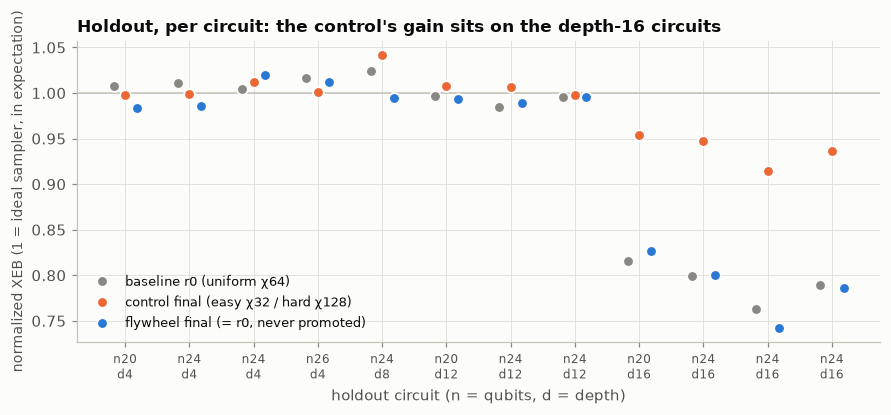

In [10]:
rows = sorted(R["baseline_r0"]["rows"], key=lambda r: (r["depth"], r["n"], r["id"]))
order = [r["id"] for r in rows]
fig, ax = plt.subplots(figsize=(8.2, 3.8))
x = np.arange(len(order))
for cfg, col, lab, dx in (("baseline_r0", C.NEUTRAL, "baseline r0 (uniform χ64)", -0.18),
                          ("control_final", C.ORANGE, "control final (easy χ32 / hard χ128)", 0.0),
                          ("flywheel_final", C.BLUE, "flywheel final (= r0, never promoted)", 0.18)):
    xm = {r["id"]: r["xeb"] for r in R[cfg]["rows"]}
    ax.plot(x + dx, [xm[i] for i in order], "o", ms=7, color=col, label=lab,
            mec=C.SURFACE, mew=1.2, zorder=3)
ax.set_xticks(x, [f"n{r['n']}\nd{r['depth']}" for r in rows], fontsize=8)
ax.axhline(1.0, color=C.AXIS, lw=1)
ax.set_ylabel("normalized XEB (1 = ideal sampler, in expectation)", fontsize=9)
ax.set_xlabel("holdout circuit (n = qubits, d = depth)")
ax.set_title("Holdout, per circuit: the control's gain sits on the depth-16 circuits")
ax.legend(fontsize=8.5, loc="lower left")
fig.tight_layout(); plt.show()

## 6 · The frozen prediction

The harness froze a prediction for the final incumbent's holdout XEB (`src/harness.py`, G3) at the `frozen_at`
time printed below: after the baseline round r0 and minutes into the flywheel arm's round-1 dispatch (two round-1
job results had already been collected), before the control arm's round 1 and before any gate decision (job-ledger
timeline as stated in the evidence appendix, `grant/make_appendix.py`). Formula: point = baseline + ½(1 − baseline),
band = [baseline, max(point, 0.999)].
We recompute the formula from the baseline, then score it against the flywheel's holdout result.

In [11]:
pred = json.loads(B.path("researcher/PREDICTIONS.jsonl").read_text().splitlines()[0])
point = base_mean + 0.5 * (1 - base_mean)
band = [base_mean, max(point, 0.999)]
actual = float(np.mean([r["xeb"] for r in R["flywheel_final"]["rows"]]))
in_band = band[0] <= actual <= band[1]
print(f"frozen {pred['frozen_at']}: point {pred['point']} band {pred['band']}")
print(f"recomputed:              point {point:.6f} band [{band[0]:.6f}, {band[1]:.6f}]")
print(f"actual flywheel holdout XEB {actual:.6f} -> in band: {in_band} (recorded: {pred['in_band']})")
check("prediction", "frozen point (6 d.p.)", pred["point"], round(point, 6))
check("prediction", "in band", pred["in_band"], in_band)

frozen 2026-10-06T07:01:55+00:00: point 0.976592 band [0.953184, 0.999]
recomputed:              point 0.976592 band [0.953184, 0.999000]
actual flywheel holdout XEB 0.927492 -> in band: False (recorded: False)


## 7 · The claims ledger

`runs/report/claims.json` maps every performance number in the report to the cloud job IDs it was
computed from. Each referenced job must exist in the job export and be COMPLETED.

In [12]:
claims = B.json("runs/report/claims.json")[1:]
by_id = {j["provider_job_id"]: j for j in jobs}
refs = [jid for c in claims for jid in c.get("evidence", {}).get("job_ids", [])]
unresolved = [j for j in refs if j not in by_id]
not_done = [j for j in refs if j in by_id and by_id[j]["run_status"] != "COMPLETED"]
no_jobs = [c["claim"] for c in claims if not c.get("evidence", {}).get("job_ids")]
print(f"claims: {len(claims)}; job references: {len(refs)}; distinct jobs: {len(set(refs))}")
print(f"unresolved references: {len(unresolved)}; references to non-COMPLETED jobs: {len(not_done)}")
print(f"claims without job IDs (derived quantities): {no_jobs}")
s = summary["claims"]
check("claims", "claims / refs / distinct (summary.json)",
      f"{s['n_claims']} / {s['n_job_refs']} / {s['n_distinct_jobs']}", f"{len(claims)} / {len(refs)} / {len(set(refs))}")
check("claims", "job refs resolving to COMPLETED jobs", len(refs), len(refs) - len(unresolved) - len(not_done))

claims: 31; job references: 432; distinct jobs: 336
unresolved references: 0; references to non-COMPLETED jobs: 0
claims without job IDs (derived quantities): ['Promotion threshold min_delta', 'Preregistered prediction in band']


## Verdict

In [13]:
n_ok = sum(c[4] for c in CHECKS)
display(Markdown(f"**{n_ok} / {len(CHECKS)} checks pass.** Disclosed deviation (not counted): "
                 + "; ".join(f"{n}: {b}" for _, n, a, b in DISCLOSED) +
                 ", the mismatching files differing only in `frozen_at` (proven in section 1).\n\n"
                 "| section | check | recorded | recomputed | match |\n|---|---|---|---|---|\n" +
                 "\n".join(f"| {s} | {n} | {a} | {b} | {'✅' if ok else '❌'} |" for s, n, a, b, ok in CHECKS) + "\n" +
                 "\n".join(f"| {s} | {n} | {a} | {b} | ⚠ disclosed |" for s, n, a, b in DISCLOSED)))
assert n_ok == len(CHECKS), "a recorded number could not be reproduced"

**24 / 24 checks pass.** Disclosed deviation (not counted): PREREGISTRATION.json == registration pin: 28/31, the mismatching files differing only in `frozen_at` (proven in section 1).

| section | check | recorded | recomputed | match |
|---|---|---|---|---|
| ledger | recorded metrics.json == ledger pin | 29/29 | 29/29 | ✅ |
| ledger | SPEC.md == registration pin | 31/31 | 31/31 | ✅ |
| ledger | EXP-006-R04 prereg differs ONLY in frozen_at | True | True | ✅ |
| ledger | EXP-006-R07 prereg differs ONLY in frozen_at | True | True | ✅ |
| ledger | EXP-006-R10 prereg differs ONLY in frozen_at | True | True | ✅ |
| jobs | campaign jobs (README) | 905 | 905 | ✅ |
| jobs | mps.cpu / cpu / pauli-path (README) | 878 / 12 / 15 | 878 / 12 / 15 | ✅ |
| jobs | holdout jobs (README) | 36 | 36 | ✅ |
| jobs | total spend USD (README) | 0.00 | 0.00 | ✅ |
| baseline | baseline mean val XEB | 0.953184 | 0.953184 | ✅ |
| baseline | noise sd (paired, ddof=1) | 0.013476 | 0.013476 | ✅ |
| baseline | min_delta = max(2·sd, 0.005) | 0.026952 | 0.026952 | ✅ |
| rounds | round decisions identical to record | 20/20 | 20/20 | ✅ |
| rounds | promotions flywheel / control | 0 / 1 | 0 / 1 | ✅ |
| holdout | paired control_vs_r0 (Δ and CI) | +0.05068 [+0.01327, +0.08967] | +0.05068 [+0.01327, +0.08967] | ✅ |
| holdout | paired flywheel_vs_r0 (Δ and CI) | -0.00652 [-0.01492, +0.00155] | -0.00652 [-0.01492, +0.00155] | ✅ |
| holdout | paired flywheel_vs_control (Δ and CI) | -0.05720 [-0.09679, -0.02103] | -0.05720 [-0.09679, -0.02103] | ✅ |
| holdout | baseline_r0 mean holdout XEB | 0.93401 | 0.93401 | ✅ |
| holdout | control_final mean holdout XEB | 0.98470 | 0.98470 | ✅ |
| holdout | flywheel_final mean holdout XEB | 0.92749 | 0.92749 | ✅ |
| prediction | frozen point (6 d.p.) | 0.976592 | 0.976592 | ✅ |
| prediction | in band | False | False | ✅ |
| claims | claims / refs / distinct (summary.json) | 31 / 432 / 336 | 31 / 432 / 336 | ✅ |
| claims | job refs resolving to COMPLETED jobs | 432 | 432 | ✅ |
| ledger | PREREGISTRATION.json == registration pin | 31/31 | 28/31 | ⚠ disclosed |

**What this audit does and does not establish.** It shows that every headline number follows,
by the preregistered rules, from the per-circuit XEB rows the harness recorded, and that those rows
are the exact bytes the ledger pinned at record time. It does **not** re-run the cloud jobs or recompute XEB from
raw counts: the count payloads and the exact statevectors they are scored against stay local, and each per-circuit XEB value is tied to a provider job ID that
BlueQubit can look up in its own systems. Exact reference probabilities are local statevector files,
regenerable from the hard-coded seeds in `src/freeze_suite.py`.